# Bank Marketing Model Experiments

This notebook compares preprocessing choices and classifiers, then examines one reserved holdout using settings chosen on the development rows. Run `01_data_audit_and_baseline.ipynb` for data provenance, exploratory analysis and the first baseline. Use the project Python environment for both notebooks.

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import Image, display
from threadpoolctl import threadpool_limits

here = Path.cwd().resolve()
root = next((p for p in (here, *here.parents) if (p / 'src/bank_experiments.py').is_file()), None)
if root is None:
    raise FileNotFoundError('Open the notebook from the project root or notebooks folder.')
sys.path.insert(0, str(root / 'src'))
from bank_experiments import RESULTS, THREADS, develop, evaluate, frozen_protocol, verify

result = root / RESULTS
protocol_path = result / 'frozen_protocol.json'
with threadpool_limits(limits=THREADS):
    if not protocol_path.is_file():
        develop(root)
    _, protocol, _ = frozen_protocol(root, require_holdout=False)

def read(name):
    return pd.read_csv(result / f'{name}.csv')

## Development Split and Feature Preparation

The final 8,238 source rows were reserved. Three expanding folds were drawn from the earlier 32,940 rows after removing 10 exact raw-row duplicates. Each fold fitted its own pipeline. Contact duration was excluded throughout. Profiles retaining scheduling fields or economic indicators served as comparisons because their availability at the targeting decision cannot be verified from this dataset. The selected profile omits the ambiguous `pdays` interval and retains `unknown` as a category.

In [2]:
display(read('folds'))
display(read('preprocessing_summary').round(4))
print('Selected profile:', protocol['profile'])
print('Predictors:', ', '.join(protocol['features']))

,fold,train_rows,validation_rows,train_last_source_row,validation_first_source_row,validation_positive_rate
0,1,8235,8235,8235,8236,0.054281
1,2,16470,8235,16472,16473,0.058531
2,3,24705,8235,24711,24712,0.110747


,profile,eligible,mean,std
0,historical_full,False,0.0708,0.0288
1,without_economic,False,0.0983,0.0780
2,precall_interval,True,0.0928,0.0605
3,precall_no_interval,True,0.0979,0.0693
4,precall_impute_unknown,True,0.0941,0.0648


Selected profile: precall_no_interval
Predictors: age, job, marital, education, default, housing, loan, previous, poutcome


## Three Classifiers and Tuning

The prior-only dummy is the reference. The three candidate classifiers use the same validation rows. Average precision is calculated separately per fold and averaged with equal weight. These scores were used for selection, so the reserved test provides the separate comparison. Training and validation AP should be interpreted alongside each period's subscription rate.

In [3]:
development = read('development_summary')
display(development.round(4))
tuning = read('tuning_folds')
display(tuning.groupby('model').candidate.nunique().rename('configurations'))
fold_scores = read('tuned_and_ensemble_folds')
display(fold_scores.pivot(index='model', columns='fold', values='average_precision').round(4))

,model,baseline_ap,development_ap,fold_ap_sd,gain_vs_baseline,mean_train_ap,selected_params
0,dummy_prior,0.0745,0.0745,0.0314,0.0000,NaN,{}
1,logistic_regression,0.0979,0.0982,0.0697,0.0003,0.0522,"{""C"": 10.0, ""class_weight"": ""balanced""}"
2,decision_tree,0.0764,0.0839,0.0463,0.0075,0.0596,"{""class_weight"": null, ""max_depth"": 6, ""min_sa..."
3,knn,0.0745,0.0806,0.0398,0.0061,0.0664,"{""n_neighbors"": 101, ""weights"": ""uniform""}"
4,soft_voting,NaN,0.1000,0.0721,NaN,0.0579,{}


model
decision_tree          17
knn                     8
logistic_regression     8
Name: configurations, dtype: int64

fold,1,2,3
model,,,
decision_tree,0.0581,0.0563,0.1374
knn,0.0574,0.0579,0.1265
logistic_regression,0.0548,0.0612,0.1786
soft_voting,0.0552,0.0616,0.1832


## Ensemble and Reserved Holdout

The ensemble averages the positive-class scores of the top two individual models by mean development AP. The selected model settings, weights, input schema and a strict `score > 0.5` rule were frozen before the holdout outcomes were read. The block comparison is descriptive. The blocks follow source order and do not represent verified calendar periods.

Saved holdout evaluation verified and reused.
Frozen model files and saved holdout results verified.
Included: logistic_regression, decision_tree
Excluded: knn
Decision rule: positive when score strictly greater than threshold 0.5


,model,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,brier,tn,fp,fn,tp,test_rows,positives
0,dummy_prior,0.3083,0.5000,0.0000,0.0000,0.0000,0.5000,0.2731,5698,0,2540,0,8238,2540
1,logistic_regression,0.5301,0.6812,0.3712,0.7724,0.5014,0.5945,0.2674,2374,3324,578,1962,8238,2540
2,decision_tree,0.4520,0.6682,0.0000,0.0000,0.0000,0.5000,0.2190,5698,0,2540,0,8238,2540
3,knn,0.4510,0.6601,0.0000,0.0000,0.0000,0.5000,0.2487,5698,0,2540,0,8238,2540
4,soft_voting,0.5400,0.6892,0.5805,0.4161,0.4848,0.6410,0.1911,4934,764,1483,1057,8238,2540


,model,fit_seconds,predict_seconds,model_bytes
0,dummy_prior,0.0023,0.0003,555
1,logistic_regression,0.3571,0.0264,2432
2,decision_tree,0.2246,0.0229,3116
3,knn,0.1101,0.8736,459116
4,soft_voting,0.5787,0.0466,4527


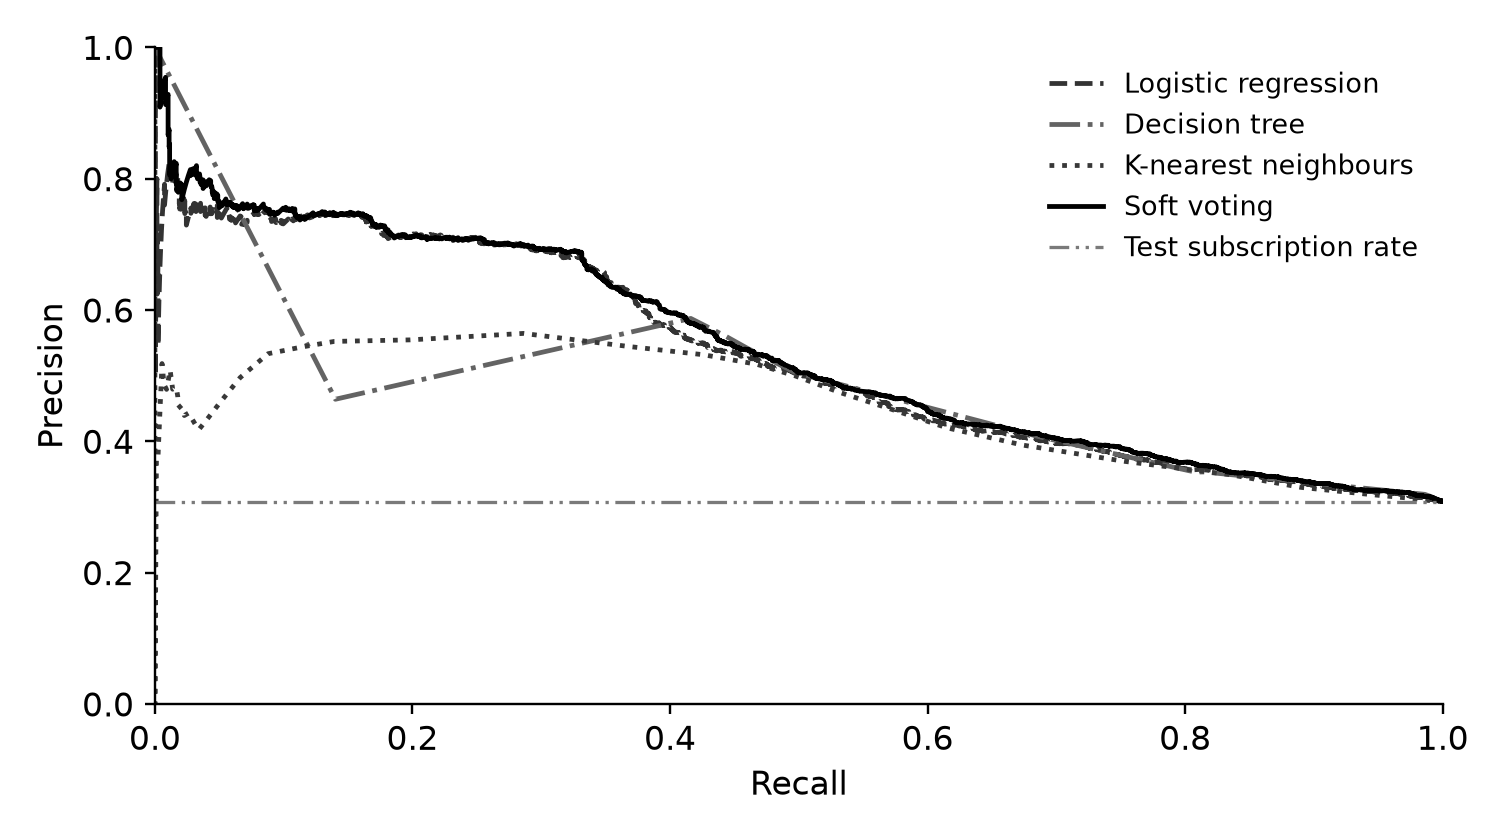

In [4]:
with threadpool_limits(limits=THREADS):
    evaluate(root)
    verify(root)
print('Included:', ', '.join(protocol['ensemble_members']))
print('Excluded:', protocol['excluded_model'])
print('Decision rule:', protocol['threshold_rule'], protocol['threshold'])
holdout = read('holdout_metrics')
display(holdout.drop(columns=['fit_seconds', 'predict_seconds', 'model_bytes']).round(4))
display(holdout[['model', 'fit_seconds', 'predict_seconds', 'model_bytes']].round(4))
display(Image(filename=str(result / 'holdout_precision_recall.png')))

In [5]:
blocks = read('holdout_block_sensitivity')
display(blocks.loc[blocks.model.isin(protocol['ensemble_members'] + ['soft_voting']),
                   ['block', 'model', 'rows', 'positive_rate', 'average_precision', 'recall']].round(4))

,block,model,rows,positive_rate,average_precision,recall
1,1,logistic_regression,2746,0.0856,0.1102,0.4596
2,1,decision_tree,2746,0.0856,0.0969,0.0000
4,1,soft_voting,2746,0.0856,0.1091,0.0511
6,2,logistic_regression,2746,0.3288,0.4333,0.7608
7,2,decision_tree,2746,0.3288,0.3745,0.0000
9,2,soft_voting,2746,0.3288,0.4334,0.3223
11,3,logistic_regression,2746,0.5106,0.6640,0.8324
12,3,decision_tree,2746,0.5106,0.5930,0.0000
14,3,soft_voting,2746,0.5106,0.6745,0.5378


## Cleaned Data and Scope

The cleaned CSV contains the selected input fields and binary target. `source_row` and `partition` record the split and stay outside the predictors. Encoding and scaling remain inside the fitted pipelines. Only the stored test predictions should be used to reproduce the displayed test metrics.

In [6]:
clean = pd.read_csv(root / 'data/processed/bank_marketing_cleaned.csv')
assert clean.source_row.is_unique
assert clean.columns.tolist() == ['source_row', 'partition', *protocol['features'], 'y']
display(clean.groupby('partition', sort=False).y.agg(rows='size', subscribers='sum'))
display(clean.head())

,rows,subscribers
partition,,
development,32940,2100
holdout,8238,2540


,source_row,partition,age,job,marital,education,default,housing,loan,previous,poutcome,y
0,0,development,56,housemaid,married,basic.4y,no,no,no,0,nonexistent,0
1,1,development,57,services,married,high.school,unknown,no,no,0,nonexistent,0
2,2,development,37,services,married,high.school,no,yes,no,0,nonexistent,0
3,3,development,40,admin.,married,basic.6y,no,no,no,0,nonexistent,0
4,4,development,56,services,married,high.school,no,no,yes,0,nonexistent,0


## Additional Checks for the Report

These checks were added after the frozen holdout comparison. They do not change the model settings or choose an operating point. The call-budget comparison uses saved holdout scores and averages the expected subscriber count over ties at each budget boundary. The duplicate sensitivity check refits the fixed logistic configuration on earlier rows only and uses the same validation blocks.

In [7]:
from bank_submission_checks import checks

extra = root / 'results/submission_checks'
with threadpool_limits(limits=THREADS):
    checks(root, reuse=True)

display(pd.Series(json.loads((extra / 'row_audit.json').read_text(encoding='utf-8')), name='count'))
display(pd.read_csv(extra / 'training_duplicate_sensitivity.csv').round(5))
display(pd.read_csv(extra / 'call_budget_sensitivity.csv')[
    ['calls', 'model', 'expected_subscribers', 'precision_at_budget', 'recall_at_budget', 'lift']
].round(3))

Saved descriptive checks verified.


holdout_exact_duplicates_within             2
holdout_exact_matches_in_development        0
unique_development_feature_profiles     12526
mixed_label_feature_profiles             1184
rows_in_mixed_label_profiles            10470
Name: count, dtype: int64

,fold,training_duplicates,training_rows,average_precision
0,1,retained,8236,0.05477
1,1,removed,8235,0.05483
2,2,retained,16473,0.06121
3,2,removed,16470,0.06121
4,3,retained,24712,0.17837
5,3,removed,24705,0.17864


,calls,model,expected_subscribers,precision_at_budget,recall_at_budget,lift
0,823,dummy_prior,253.753,0.308,0.100,1.000
1,823,logistic_regression,584.000,0.710,0.230,2.301
2,823,decision_tree,394.002,0.479,0.155,1.553
3,823,knn,455.947,0.554,0.180,1.797
4,823,soft_voting,583.500,0.709,0.230,2.299
5,1647,dummy_prior,507.815,0.308,0.200,1.000
6,1647,logistic_regression,975.000,0.592,0.384,1.920
7,1647,decision_tree,953.173,0.579,0.375,1.877
8,1647,knn,901.009,0.547,0.355,1.774
9,1647,soft_voting,995.900,0.605,0.392,1.961
